In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

In [2]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

In [3]:

train_df = pd.read_csv(
    "/kaggle/input/datasets/oddrationale/mnist-in-csv/mnist_train.csv"
)

test_df = pd.read_csv(
    "/kaggle/input/datasets/oddrationale/mnist-in-csv/mnist_test.csv"
)

X = train_df.drop(columns=["label"]).to_numpy(dtype=np.float32)
y = train_df["label"].to_numpy(dtype=np.int64)

X_test = test_df.drop(columns=["label"]).to_numpy(dtype=np.float32)
y_test = test_df["label"].to_numpy(dtype=np.int64)

# Normalize
X /= 255.0
X_test /= 255.0

# Train / Validation split
rng = np.random.default_rng(42)
indices = rng.permutation(len(X))

train_indices = indices[:54000]
val_indices = indices[54000:]

X_train, y_train = X[train_indices], y[train_indices]
X_val, y_val = X[val_indices], y[val_indices]

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(54000, 784) (54000,)
(6000, 784) (6000,)
(10000, 784) (10000,)


In [4]:

X_train_tensor = torch.from_numpy(X_train)
y_train_tensor = torch.from_numpy(y_train)

X_val_tensor = torch.from_numpy(X_val)
y_val_tensor = torch.from_numpy(y_val)

X_test_tensor = torch.from_numpy(X_test)
y_test_tensor = torch.from_numpy(y_test)

train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor, y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor, y_test_tensor
)

batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [5]:
class ANN(nn.Module):

    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)

        return x


model = ANN().to(device)

print(model)

ANN(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)


In [6]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [7]:
import copy

epochs = 20
patience = 4

best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(epochs):

    model.train()

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward propagation
        logits = model(X_batch)

        # Calculate loss
        loss = criterion(logits, y_batch)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

    model.eval()

    train_loss_sum = 0.0
    train_correct = 0
    val_loss_sum = 0.0
    val_correct = 0

    with torch.no_grad():

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            train_loss_sum += loss.item() * len(y_batch)
            train_correct += (
                logits.argmax(dim=1) == y_batch
            ).sum().item()

        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            val_loss_sum += loss.item() * len(y_batch)
            val_correct += (
                logits.argmax(dim=1) == y_batch
            ).sum().item()

    train_loss = train_loss_sum / len(train_dataset)
    val_loss = val_loss_sum / len(val_dataset)

    train_acc = 100 * train_correct / len(train_dataset)
    val_acc = 100 * val_correct / len(val_dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break

model.load_state_dict(best_model_state)


Epoch 1/20 | Train Loss: 0.1794 | Val Loss: 0.1846 | Train Acc: 94.72% | Val Acc: 94.45%
Epoch 2/20 | Train Loss: 0.1203 | Val Loss: 0.1417 | Train Acc: 96.44% | Val Acc: 95.78%
Epoch 3/20 | Train Loss: 0.0803 | Val Loss: 0.1069 | Train Acc: 97.59% | Val Acc: 96.70%
Epoch 4/20 | Train Loss: 0.0581 | Val Loss: 0.0963 | Train Acc: 98.39% | Val Acc: 97.25%
Epoch 5/20 | Train Loss: 0.0493 | Val Loss: 0.0925 | Train Acc: 98.51% | Val Acc: 97.20%
Epoch 6/20 | Train Loss: 0.0371 | Val Loss: 0.0818 | Train Acc: 98.90% | Val Acc: 97.52%
Epoch 7/20 | Train Loss: 0.0383 | Val Loss: 0.0996 | Train Acc: 98.80% | Val Acc: 97.27%
Epoch 8/20 | Train Loss: 0.0208 | Val Loss: 0.0805 | Train Acc: 99.37% | Val Acc: 97.57%
Epoch 9/20 | Train Loss: 0.0202 | Val Loss: 0.0876 | Train Acc: 99.44% | Val Acc: 97.75%
Epoch 10/20 | Train Loss: 0.0151 | Val Loss: 0.0902 | Train Acc: 99.55% | Val Acc: 97.83%
Epoch 11/20 | Train Loss: 0.0145 | Val Loss: 0.0917 | Train Acc: 99.56% | Val Acc: 97.73%
Epoch 12/20 | Train

<All keys matched successfully>

In [8]:
model.eval()

test_loss_sum = 0.0
test_correct = 0

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        test_loss_sum += loss.item() * len(y_batch)
        test_correct += (
            logits.argmax(dim=1) == y_batch
        ).sum().item()

test_loss = test_loss_sum / len(test_dataset)
test_acc = 100 * test_correct / len(test_dataset)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

Test Loss: 0.0825
Test Accuracy: 97.72%


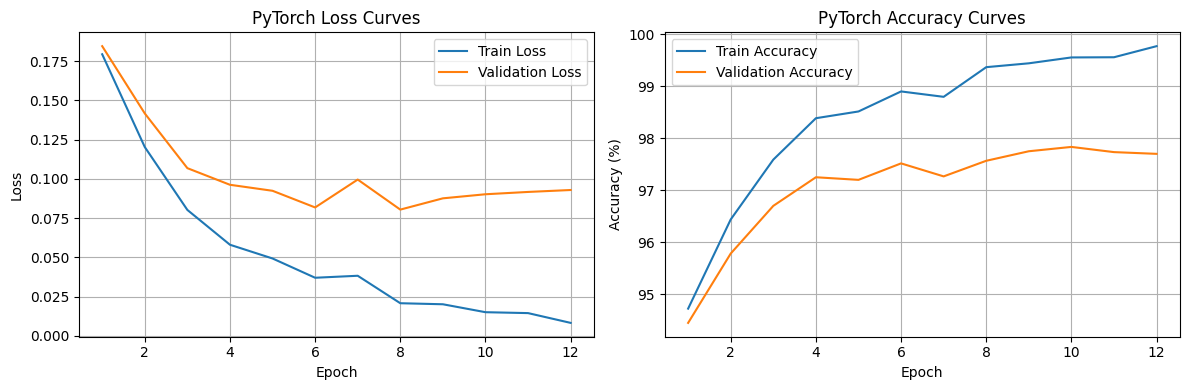

In [9]:
import matplotlib.pyplot as plt

epoch_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epoch_range, history["train_loss"], label="Train Loss")
plt.plot(epoch_range, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PyTorch Loss Curves")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epoch_range, history["train_acc"], label="Train Accuracy")
plt.plot(epoch_range, history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("PyTorch Accuracy Curves")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()